In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score ,
    precision_score,
    recall_score ,
    f1_score,
    classification_report , 
    confusion_matrix ,
    ConfusionMatrixDisplay
)

In [6]:
df = pd.read_csv("complaints_train_5000.csv")
df.head()

,Product,Consumer complaint narrative,Complaint ID
0,"Credit reporting, credit repair services, or o...","In XX/XX/XXXX, my XXXX XXXX was repossessed. I...",3056081
1,Debt collection,XXXX OF XXXX REPRESENTING A PAYDAY LOAN COMPAN...,2003744
2,Debt collection,I have paid my son 's all bills at XXXX XXXX X...,1807880
3,Credit reporting,i did not allow this company to do a hard cred...,2262473
4,Credit reporting,Numerous entries on credit report for the same...,1776220


In [7]:
print("Toplam Kayit : " , df.shape[0] )

print("Toplam Kategori Sayisi : " , df["Product"].nunique())

print(df["Product"].value_counts())

Toplam Kayit :  5000
Toplam Kategori Sayisi :  4
Product
Credit reporting, credit repair services, or other personal consumer reports    1250
Debt collection                                                                 1250
Credit reporting                                                                1250
Mortgage                                                                        1250
Name: count, dtype: int64


In [8]:
df["Consumer complaint narrative"].duplicated().sum()

np.int64(0)

Soru : Bir veri setinde tekrarlanan metinler bulunması her zaman kötü müdür?
Aynı metnin birden fazla kez bulunması hangi durumlarda sorun oluşturabilir?

In [9]:
#Tekrarlanan metinler her zaman kötü değildir. Geerçek veri dağılımını temsil ediyor olabilirler. Ancak aynı veri hem eğitim hem de test setinde bulunuyorsa data leakage oluşabilir. Fazla tekrar overfitting riskini de attırabilir. Model belirli bir örüntüyü takip edip performansını düşürebilir.

In [10]:
label_map = {
    "Credit reporting, credit repair services, or other personal consumer reports": 1,
    "Debt collection": 2,
    "Credit reporting": 3,
    "Mortgage": 4
}

df["label"] = df["Product"].map(label_map)

In [32]:
import re
def clean_text(text):

    if pd.isna(text):
        return ""

    # Küçük harfe dönüştür
    text = str(text).lower()

    # XXXX gibi gizlenmiş bilgileri kaldır
    text = re.sub(r"\bx{2,}\b", " ", text)

    # Noktalama işaretlerini kaldır
    text = re.sub(r"[^\w\s]", " ", text)

    # Fazla boşlukları temizle
    text = re.sub(r"\s+", " ", text).strip()

    return text

In [33]:
df["Consumer complaint narrative"] = df["Consumer complaint narrative"].apply(clean_text)

In [34]:
df.head()

,Product,Consumer complaint narrative,Complaint ID,label
0,"Credit reporting, credit repair services, or o...",in my was repossessed i recently pulled my cre...,3056081,1
1,Debt collection,of representing a payday loan company spotloan...,2003744,2
2,Debt collection,i have paid my son s all bills at medicine or ...,1807880,2
3,Credit reporting,i did not allow this company to do a hard cred...,2262473,3
4,Credit reporting,numerous entries on credit report for the same...,1776220,3


In [35]:
X = df["Consumer complaint narrative"]
y = df["label"]

In [36]:
print("X shape :" ,X.shape)
print("Y shape :" , y.shape)

print(X.head(5))
print(y.head(5))

X shape : (5000,)
Y shape : (5000,)
0    in my was repossessed i recently pulled my cre...
1    of representing a payday loan company spotloan...
2    i have paid my son s all bills at medicine or ...
3    i did not allow this company to do a hard cred...
4    numerous entries on credit report for the same...
Name: Consumer complaint narrative, dtype: str
0    1
1    2
2    2
3    3
4    3
Name: label, dtype: int64


Soru : Neden Complaint ID sütununu model girdisi olarak kullanmıyoruz?
Bir model, kayıt numaralarını kullanarak anlamlı bir ürün kategorisi tahmini yapabilir mi   ?

In [37]:
#ID sütünü kayıtları benzersiz şekilde tanımlayan bir sütündür. Hedef değişken hakkında anlamlı bilgi içermez.

In [38]:
X_train , X_test , y_train , y_test = train_test_split(X , y , test_size=0.2 , random_state=42 , stratify=y )

In [39]:
print("Train :" ,  X_train.shape )
print("Test :" , X_test.shape )

Train : (4000,)
Test : (1000,)


Soru : stratify=y kullanmazsak ne olabilir?
Özellikle çok az örneği bulunan bir kategorimiz olsaydı nasıl bir problem yaşayabilirdik?

In [40]:
#train ve test setlerindeki sinif dagilimlari dengesiz olabilirdi. Özellikle az örneği bulunan kategoriler test veya eğitim setinde hiç bulunmayabilir.

In [41]:
common_texts = set(X_train).intersection(set(X_test))

print("Ortak metin sayısı:", len(common_texts))

Ortak metin sayısı: 0


Soru : Aynı metinleri iki kümeden çıkarmak, bütün Data Leakage problemlerini çözer mi?

In [42]:
#Aynı metinleri iki kümeden çıkarmak , bütün Data Leakage problemini çözmez. Çünkü birbirine çok benzeyen metinler , aynı kaynaktan gelen kayıtlar veya veri ön işleme sırasında test verisinin kullanılması da sızıntıya neden olabilir.


In [43]:
tf_idf_word_vectorizer  = TfidfVectorizer(max_features=1500)

X_train_tfidf = tf_idf_word_vectorizer.fit_transform(X_train)
X_test_tfidf = tf_idf_word_vectorizer.transform(X_test)


In [44]:
print("Shape :"  , X_train_tfidf.shape)
print("Type : " , X_train_tfidf.dtype)

Shape : (4000, 1500)
Type :  float64


In [45]:
print("Shape :"  , X_test_tfidf.shape)
print("Type : " , X_test_tfidf.dtype)

Shape : (1000, 1500)
Type :  float64


In [46]:
# 1. Kelime dağarcığını al
feature_names = tf_idf_word_vectorizer.get_feature_names_out()

# 2. İlk 20 özelliği göster
print("İlk 20 özellik:", feature_names[:20])

# 3. Toplam özellik sayısı
print("Toplam özellik:", len(feature_names))

# 4. İngilizce kelimeleri incele
print("İngilizce terimler:", feature_names[500:520])

İlk 20 özellik: ['00' '10' '100' '1000' '10000' '11' '12' '120' '1200' '13' '14' '15' '16'
 '17' '18' '19' '1st' '20' '200' '2000']
Toplam özellik: 1500
İngilizce terimler: ['evidence' 'ex' 'exact' 'exactly' 'except' 'exhibit' 'expect' 'expenses'
 'experian' 'experience' 'expired' 'explain' 'explained' 'explaining'
 'explanation' 'extended' 'extension' 'extra' 'extremely' 'fact']


Soru : TF-IDF matrisinin neden çoğunlukla sıfırlardan oluştuğunu araştır.
Sparse Matrix nedir?    
X_train_tfidf.toarray() Neden büyük veri setlerinde gereksiz yere kullanmamalıyız?

In [47]:
#TF-IDF matrisinin çoğunlukla sıfırlardan oluşmasının nedeni , her metnin kelime darcığındaki kelimelerin yalnızca küçük bir kısmını içermesidir. Bir kelime ilgili metinde bulunmuyorsa TF-IDf değeri sıfır olur.
#Sparse Matrix , elemanların büyük çoğunluğu sıfırlardan oluşan matrisleri bellekte verimli saklamak için kullanılan bir veri yapısıdır. Bellekte bütün sıfırları saklamak yerine sıfır olmayan değerleri ve konumları tutar.
#Çünkü X_train_tfidf.toarray() işlemi Sparse Matrix'i Dense Matrix'e dçnüştürür. Bu da tüm sıfırlarda dahil bütün elemanları belleğe alacağı anlamına gelir. Bu durum Ram tüketimini ciddi şekilde attırabilir.

In [48]:
model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model.fit(X_train_tfidf , y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

In [49]:
y_pred = model.predict(X_test_tfidf)

In [50]:
comparison = pd.DataFrame({
    "Gerçek": y_test[:10].to_numpy(),
    "Tahmin": y_pred[:10]
})

comparison["Doğru mu?"] = comparison["Gerçek"] == comparison["Tahmin"]

print(comparison)

   Gerçek  Tahmin  Doğru mu?
0       2       2       True
1       3       3       True
2       1       2      False
3       4       4       True
4       1       1       True
5       3       3       True
6       2       2       True
7       3       1      False
8       1       2      False
9       1       3      False


In [51]:
new_complaint = [
    "My credit report contains incorrect information."
]

new_complaint = tf_idf_word_vectorizer.transform(new_complaint)

In [52]:
model.predict(new_complaint)

array([3])

Soru : Logistic Regression ismine rağmen neden sınıflandırma problemlerinde kullanılıyor?

In [53]:
#Logistic Regression, isminde Regression geçmesine rağmen sınıflandırma için kullanılan bir algoritmadır. Öncelikle girdilerin doğrusal kombinasyonunu hesaplar. Ardından Sigmoid veya Softmax fonksiyonu kullanarak sınıf olasılıklarını elde eder.

In [54]:
# 1. Accuracy
accuracy = accuracy_score(y_test, y_pred)

# 2. Macro Precision
precision = precision_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

# 3. Macro Recall
recall = recall_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

# 4. Macro F1
f1 = f1_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

# Sonuçlar
print(f"Accuracy:        {accuracy * 100:.2f}%")
print(f"Macro Precision: {precision * 100:.2f}%")
print(f"Macro Recall:    {recall * 100:.2f}%")
print(f"Macro F1:        {f1 * 100:.2f}%")

# 5. Classification Report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

Accuracy:        72.30%
Macro Precision: 71.76%
Macro Recall:    72.30%
Macro F1:        71.97%

Classification Report:
              precision    recall  f1-score   support

           1       0.58      0.52      0.55       250
           2       0.79      0.81      0.80       250
           3       0.61      0.63      0.62       250
           4       0.88      0.93      0.90       250

    accuracy                           0.72      1000
   macro avg       0.72      0.72      0.72      1000
weighted avg       0.72      0.72      0.72      1000



Soru : 1- Macro-F1 ile Weighted-F1 arasındaki fark nedir?
2- Macro-F1 neden bütün sınıflara eşit önem verir?
3- Accuracy yüksekken Macro-F1 düşük olabilir mi?
4- Bir sınıfta Precision yüksek, Recall düşükse nasıl yorumlarsın?

In [55]:
#1- Macro-F1 bütün sınıfların F1 skorlarının eşit ağırlıklı ortalamasıdır. Weighted-F1 ise sınıfların örnek sayılarını dikkate alır. Dengesiz veri setlerinde Macro-F1, azınlık sınıflarının performansını daha görünür kılar.
#2- Çünkü her sınıfın F1 skorunu örnek sayısından bağımsız olarak hesaplar ve aritmetik ortalamasını alır.
#3- Evet. Özellikle dengesiz veri setlerinde model çoğunluk sınıfını doğru tahmin ederek yüksek Accuracy elde edebilir ancak azınlık sınıflarında başarısız olduğu için Macro-F1 düşük kalabilir.
#4- Modelin pozitif tahminlerinin çoğu doğrudur ancak gerçek pozitif örneklerin önemli bir kısmını kaçırıyordur. Yani False Negative sayısı yüksektir.

Matrix Shape: (4, 4)
Correct Predictions: 723
Incorrect Predictions: 277


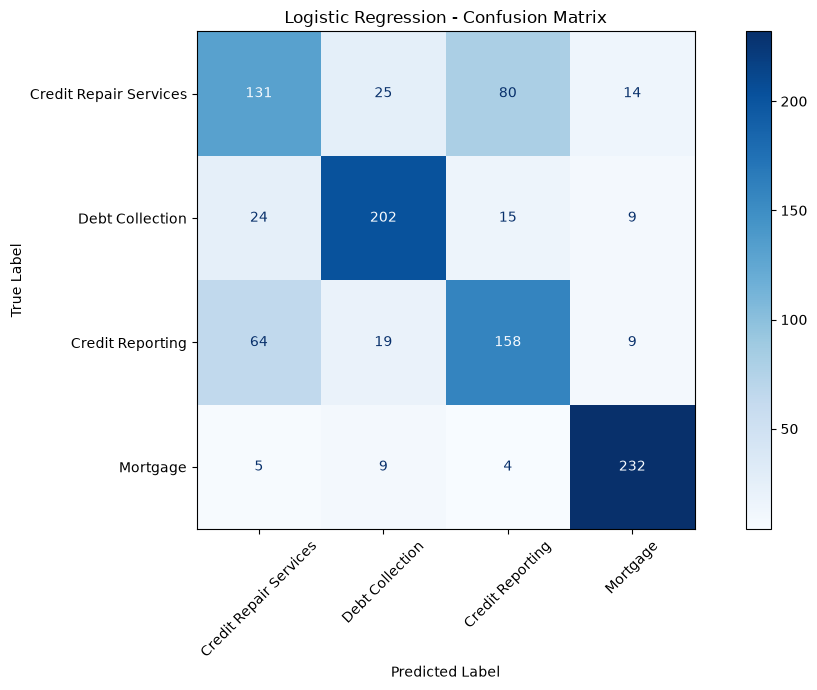

In [56]:
#1. Confusion Matrix oluştur
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[1, 2, 3, 4]
)

# 2. Matris boyutunu kontrol et
print("Matrix Shape:", cm.shape)

# 3. Doğru tahmin sayısı
correct = np.trace(cm)

# 4. Yanlış tahmin sayısı
incorrect = cm.sum() - correct

print("Correct Predictions:", correct)
print("Incorrect Predictions:", incorrect)

# 5. Sınıf isimlerini al
class_names = [
    "Credit Repair Services",
    "Debt Collection",
    "Credit Reporting",
    "Mortgage"
]

# 6. Görselleştir
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(11, 7))

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax,
    xticks_rotation=45
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.tight_layout()
plt.show()

In [57]:
# 1. Sonuçları DataFrame'e aktar
results_df = pd.DataFrame({
    "text": X_test.reset_index(drop=True),
    "true_label": np.asarray(y_test),
    "predicted_label": np.asarray(y_pred)
})

# 2. Yanlış tahminleri filtrele
wrong_df = results_df[
    results_df["true_label"] != results_df["predicted_label"]
].copy()

# 3. Etiketleri kategori isimlerine dönüştür
reverse_map = {v: k for k, v in label_map.items()}

wrong_df["true_category"] = wrong_df["true_label"].map(reverse_map)
wrong_df["predicted_category"] = wrong_df["predicted_label"].map(reverse_map)

# 4. Yanlış tahmin sayısı
print("Yanlış tahmin sayısı:", len(wrong_df))

# 5. İlk 10 yanlış tahmin
display(
    wrong_df[
        ["text", "true_category", "predicted_category"]
    ].head(10)
)

Yanlış tahmin sayısı: 277


,text,true_category,predicted_category
2,i settled the accont with capital one for doll...,"Credit reporting, credit repair services, or o...",Debt collection
7,on my credit report it shows that i have an op...,Credit reporting,"Credit reporting, credit repair services, or o..."
8,was given a opportunity to present verificatio...,"Credit reporting, credit repair services, or o...",Debt collection
9,ive attached my credit reports were the fraud ...,"Credit reporting, credit repair services, or o...",Credit reporting
15,this issue has been going on too long and has ...,Mortgage,"Credit reporting, credit repair services, or o..."
19,i have an issue with a company called montery ...,Debt collection,Mortgage
20,this account first showed as a collections acc...,Debt collection,Credit reporting
23,there is no option for my complaint below is m...,"Credit reporting, credit repair services, or o...",Credit reporting
27,my husband and i are not able to file a disput...,Credit reporting,Mortgage
28,the company pulled my credit without my author...,Mortgage,"Credit reporting, credit repair services, or o..."


Soru :1. Modelin en başarılı olduğu kategori hangisi?
2. En düşük Recall hangi kategoride?
3. Model en çok hangi iki kategoriyi karıştırıyor?
4. Bu kategorilerin şikâyet metinleri birbirine benziyor mu?

In [ ]:
# 1- Modelin en başarılı olduğu kategori Mortgage. Bu kategoride 250 şikâyetin 232'sini doğru tahmin etmiş. Recall değeri %92.8.
# 2- En düşük Recall, Credit Repair Services kategorisinde. 250 şikâyetin yalnızca 131'i doğru tahmin edilmiş. Recall değeri %52.4.
# 3- Model en çok Credit Repair Services ve Credit Reporting kategorilerini karıştırıyor. Bu iki kategori arasında toplam 144 yanlış tahmin var.
# 4-Evet, büyük ihtimalle benziyor. Çünkü her iki kategoride de kredi raporlarındaki hatalar, yanlış bilgiler ve kredi skoruyla ilgili şikâyetler bulunabiliyor. Bu yüzden model benzer kelimeler nedeniyle iki kategoriyi ayırt etmekte zorlanıyor. Ancak bunu kesinleştirmek için şikâyet metinlerini incelemek gerekir.

In [58]:
tf_idf_word_vectorizer2  = TfidfVectorizer(max_features=3000)

X_train_tfidf = tf_idf_word_vectorizer2.fit_transform(X_train)
X_test_tfidf = tf_idf_word_vectorizer2.transform(X_test)


In [59]:
model.fit(X_train_tfidf , y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

In [60]:
y_pred = model.predict(X_test_tfidf)

In [61]:
# 1. Accuracy
accuracy = accuracy_score(y_test, y_pred)

# 2. Macro Precision
precision = precision_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

# 3. Macro Recall
recall = recall_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

# 4. Macro F1
f1 = f1_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

# Sonuçlar
print(f"Accuracy:        {accuracy * 100:.2f}%")
print(f"Macro Precision: {precision * 100:.2f}%")
print(f"Macro Recall:    {recall * 100:.2f}%")
print(f"Macro F1:        {f1 * 100:.2f}%")

# 5. Classification Report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

Accuracy:        72.60%
Macro Precision: 72.09%
Macro Recall:    72.60%
Macro F1:        72.31%

Classification Report:
              precision    recall  f1-score   support

           1       0.58      0.55      0.56       250
           2       0.79      0.80      0.79       250
           3       0.63      0.62      0.62       250
           4       0.88      0.94      0.91       250

    accuracy                           0.73      1000
   macro avg       0.72      0.73      0.72      1000
weighted avg       0.72      0.73      0.72      1000



Soru : 1- Daha fazla özellik her zaman daha iyi model anlamına gelir mi?
2- Özellik sayısı arttığında overfitting riski değişebilir mi?
3- TF-IDF parametrelerini artırmak eğitim süresini nasıl etkiler?
4- İki model benzer başarı gösterirse hangisini tercih edersin?1

In [ ]:
# 1-Hayır. Daha fazla özellik modele ek bilgi sağlayabilir ancak gereksiz veya gürültülü özellikler modelin performansını düşürebilir. Önemli olan özellik sayısı değil, özelliklerin kalitesidir.
# 2- Evet, artabilir. Model çok fazla özellik kullandığında eğitim verisindeki gereksiz detayları öğrenebilir. Bu da yeni veriler üzerindeki başarısını düşürebilir. Regularization ve feature selection ile bu riski azaltabiliriz.
# 3- Örneğin max_features veya ngram_range değerlerini artırırsak daha fazla özellik oluşur. Bu da bellek kullanımını ve eğitim süresini artırabilir. Ancak modelin başarısı her zaman artmaz.
# 4- Ben daha basit, daha hızlı ve daha az kaynak tüketen modeli tercih ederim. Ancak sadece Accuracy'ye bakmam, Precision, Recall ve F1-score değerlerini de karşılaştırırım. Örneğin bizim modellerimizde Accuracy değerleri %72.6 ve %72.3. Aradaki fark çok küçük. Bu nedenle modellerin eğitim süresini, karmaşıklığını ve sınıf bazındaki performanslarını karşılaştırarak karar veririm.
